# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 01 against the shared **union** control pool and graph-smoothed. Here we
render them as deliverables (raw per-cell scores, so 10x dropout is visible) and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into *distinct arms*
with Crest terminal. A non-branching manifold instead shows the embryonic programs present as one
developmental **geography** with Crest as an **inverse/terminal gradient** (§1) rather than resolved
into two competing arms. In Qian 2020 the honest PPT tree test (02) found **no Gast-high arm** (all
tips Gast-negative), so there is no bifurcation; and the dominant developmental contrast is the
**spatial Crest↔Gast inverse gradient** (smoothed r ≈ −0.49, batch-confirmed within patients), with
Gast and pSom overlapping toward the origin. This is the non-branching pattern, so **Gate 2 = GO**;
with no Gast↔pSom bifurcation the cross-repression test is **Gate 3 = NA**. Crest forms an inverse
gradient to Gast, **not** an enrichment on a Gast arm (no arms exist), so **no inversion flag**.
Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
name = os.path.basename(os.getcwd())                     # 'Qian2020_Breast-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # 'Breast'
dataname = re.sub(r'-\d+$', '', name)                    # 'Qian2020_Breast' (raw data has no -1 suffix)
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dataname)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads (-1)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)  # figs (-1)
pth_cb   = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
sys.path.append(os.path.join(pth, 'mesencontext'))
print('dataset:', name, '| category:', cat)
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
from scipy.stats import spearmanr

dataset: Qian2020_Breast-1 | category: Breast


### Load the rooted manifold (signatures scored + smoothed in 01)

In [2]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
print('cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
for src, lab_ in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')

cells: 4801 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: (i) the dominant developmental contrast is the
**spatial** Gast↔Crest inverse gradient (smoothed anti-correlation); (ii) the honest PPT tree (02)
found no Gast-high arm, so there is no Gast↔pSom bifurcation; (iii) along the fitted somitogenesis
body-axis the origin programs (Gast, pSom) decline from the root, while neural crest is the transverse
inverse gradient. The read is led by the signature **geography on the embedding**, per the spec's
visual-judgement basis, not a single scalar.

In [3]:
print('smoothed spatial correlations (developmental geography):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed; fitted body-axis = somitogenesis):')
for lab_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[lab_]); print(f'  {lab_}: rho = {rho:+.3f}')
print('  (origin programs Gast/pSom decline from the root; Crest weakly structured along this axis,')
print('   its geography is the transverse Gast<->Crest inverse gradient above)')
print('\nglobal module means: Gast %.3f  pSom %.3f  Crest %.3f -> pSom & Crest > Gast (Linear-pSom/Crest)'
      % (adata.obs['Gast'].mean(), adata.obs['pSom'].mean(), adata.obs['Crest'].mean()))
print('\nGate 2: embryonic programs present as one geography; Crest an inverse gradient to Gast')
print('        (spatial r=-0.49); no Gast-high arm (PPT tips all Gast-negative) -> GO (non-branching)')
print('Gate 3: no Gast<->pSom bifurcation -> NA | Crest inverse gradient (not on a Gast arm) -> no inversion flag')

smoothed spatial correlations (developmental geography):
  Gast_sm vs pSom_sm: r = -0.22
  Crest_sm vs Gast_sm: r = -0.49
  Crest_sm vs pSom_sm: r = +0.18

gradient along pseudotime (Spearman rho on smoothed; fitted body-axis = somitogenesis):
  Gast_sm: rho = -0.198
  pSom_sm: rho = -0.239
  Crest_sm: rho = -0.077
  (origin programs Gast/pSom decline from the root; Crest weakly structured along this axis,
   its geography is the transverse Gast<->Crest inverse gradient above)

global module means: Gast -0.020  pSom 0.031  Crest 0.013 -> pSom & Crest > Gast (Linear-pSom/Crest)

Gate 2: embryonic programs present as one geography; Crest an inverse gradient to Gast
        (spatial r=-0.49); no Gast-high arm (PPT tips all Gast-negative) -> GO (non-branching)
Gate 3: no Gast<->pSom bifurcation -> NA | Crest inverse gradient (not on a Gast arm) -> no inversion flag


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, developmental origin left→right (`X_umap_lin`), `size=30`, plasma,
**raw** (not smoothed) score per cell so 10x dropout is visible. Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


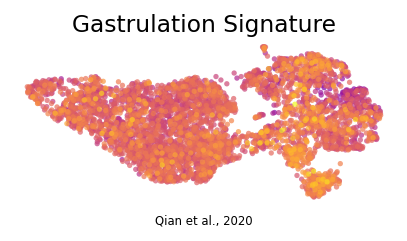

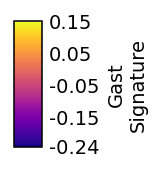

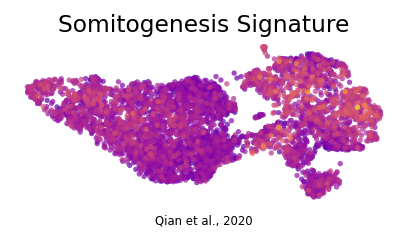

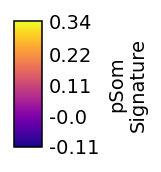

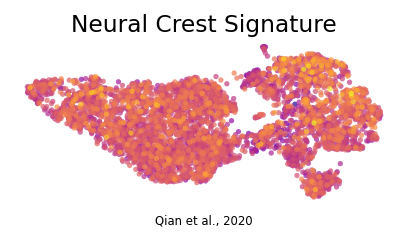

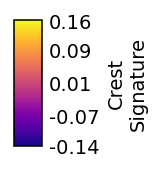

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature', 'pSom':'Somitogenesis Signature', 'Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo_, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo_, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [5]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (4801, 17670)
